# Tugas Pendahuluan
### Nama: Meisya Natasafira
### NIM: 24031554174

## 1.1 Persiapan dan Perkenalan Lingkungan

Pada tahap ini dilakukan persiapan lingkungan pengembangan menggunakan virtual environment agar dependensi proyek terisolasi dari proyek Python lainnya. Lingkungan ini digunakan untuk menjalankan Python, mengakses database Neo4j, mengolah dataset RetailRocket, serta melakukan analisis dan pemodelan rekomendasi item.

In [1]:
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USER = "neo4j"
PASSWORD = "12345678"
DATABASE = "neo4j"

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


## 1.2 Mempelajari Penggunaan Driver Neo4j

Bagian ini mempelajari penggunaan Neo4j Driver untuk menghubungkan Python dengan database Neo4j. Contoh yang digunakan adalah pembuatan simpul berlabel `Person` dan relasi `KNOWS`, kemudian mengambil data teman berdasarkan nama seseorang melalui query Cypher.

In [2]:
def add_friend(driver, name, friend_name):
    query = """
    MERGE (a:Person {name: $name})
    MERGE (b:Person {name: $friend_name})
    MERGE (a)-[:KNOWS]->(b)
    """

    with driver.session(database=DATABASE) as session:
        session.run(
            query,
            name=name,
            friend_name=friend_name
        )


def print_friends(driver, name):
    query = """
    MATCH (a:Person)-[:KNOWS]->(friend)
    WHERE a.name = $name
    RETURN friend.name AS friend_name
    ORDER BY friend.name
    """

    with driver.session(database=DATABASE) as session:
        records = session.run(query, name=name)
        for record in records:
            print(record["friend_name"])

In [3]:
add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")

print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Pertanyaan Pendahuluan (Checkpoint)

#### 1. Nama database yang digunakan

Database yang digunakan pada contoh tutorial adalah `neo4j`, sesuai dengan nama database yang ditentukan pada parameter koneksi.

#### 2. Akses lain untuk mengakses database dalam satu instance

Database dapat diakses melalui Neo4j Browser menggunakan Cypher, melalui Neo4j Driver dari Python, maupun melalui perangkat pengelolaan Neo4j lainnya. Perintah Cypher yang umum digunakan meliputi `MATCH` untuk membaca data, `CREATE` untuk membuat simpul atau relasi, `MERGE` untuk membuat data jika belum tersedia, `SET` untuk memperbarui properti, dan `DELETE` untuk menghapus data. Database tujuan ditentukan melalui sesi atau parameter database pada driver, sesuai hak akses pengguna.

#### 3. Jenis graf pertemanan yang dibuat

Graf pertemanan tersebut merupakan graf berarah karena relasi `KNOWS` memiliki arah dari satu simpul `Person` ke simpul `Person` lainnya. Simpul merepresentasikan orang, sedangkan relasi merepresentasikan hubungan pertemanan.

In [4]:
driver.close()

## 1.3 Melakukan Proses Impor Data RetailRocket ke Database Neo4j

Dataset RetailRocket berisi catatan interaksi pengunjung terhadap produk. Kolom utamanya meliputi `timestamp`, `visitorid`, `event`, `itemid`, dan `transactionid`.

Pada proses impor, pengunjung direpresentasikan sebagai simpul `Visitor`, sedangkan produk direpresentasikan sebagai simpul `Item`. Jenis interaksi direpresentasikan menggunakan relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Data dimasukkan secara bertahap menggunakan mekanisme batch agar proses impor lebih efisien.

In [5]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

csv_path = DATA_DIR / "events.csv"

df = pd.read_csv(csv_path)

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

display(df.head())
display(df.info())

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


None

# BAB 2 Soal

Bab ini membahas pengolahan data dan analisis interaksi pada dataset RetailRocket menggunakan Neo4j dan Python. Pembahasan dibagi menjadi dua bagian, yaitu Wrangling dan Exploratory Data Analysis (EDA), serta Analytics untuk membangun dan mengevaluasi rekomendasi item.

## 2.1 Wrangling dan EDA

Bagian ini berfokus pada pemilihan periode data, pemfilteran interaksi, eksplorasi struktur graf Neo4j, serta pembentukan Vector Space Model (VSM) untuk simpul User dan Item. Hasil eksplorasi digunakan untuk menentukan proyeksi yang lebih efisien, menghitung kemiripan antaritem, dan menampilkan perubahan struktur graf setelah relasi kemiripan ditambahkan.

In [6]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("data")
df = pd.read_csv(DATA_DIR / "events.csv")

# Pastikan kolom timestamp valid
df["timestamp"] = pd.to_numeric(
    df["timestamp"], errors="coerce"
)
df = df.dropna(subset=["timestamp"])
df["timestamp"] = df["timestamp"].astype("int64")

# Konversi untuk pemeriksaan tanggal
df["datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", utc=True
)

# Batas awal inklusif, batas akhir eksklusif
p1_start = pd.Timestamp("2015-05-24", tz="UTC")
p1_end   = pd.Timestamp("2015-06-23", tz="UTC")

p2_start = pd.Timestamp("2015-06-23", tz="UTC")
p2_end   = pd.Timestamp("2015-07-09", tz="UTC")

p1 = df[
    (df["datetime"] >= p1_start) &
    (df["datetime"] < p1_end)
].copy()

p2 = df[
    (df["datetime"] >= p2_start) &
    (df["datetime"] < p2_end)
].copy()

print("Jumlah data asli:", len(df))
print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))

print("\nRentang P1:")
print(p1["datetime"].min(), "sampai", p1["datetime"].max())

print("\nRentang P2:")
print(p2["datetime"].min(), "sampai", p2["datetime"].max())

Jumlah data asli: 2756101
Jumlah data P1: 606634
Jumlah data P2: 329403

Rentang P1:
2015-05-24 00:00:04.950000+00:00 sampai 2015-06-22 23:59:58.839000+00:00

Rentang P2:
2015-06-23 00:00:01.550000+00:00 sampai 2015-07-08 23:59:57.296000+00:00


### 2.1.1 Penentuan Periode dan Filter Data

Data interaksi dibagi menjadi dua periode. Periode P1 digunakan sebagai data training, sedangkan P2 digunakan sebagai data testing.

- **P1 (training):** 24 Mei 2015 sampai 22 Juni 2015.
- **P2 (testing):** 23 Juni 2015 sampai 8 Juli 2015.

Filter diterapkan pada kolom `timestamp` dengan memperhatikan bahwa timestamp dataset menggunakan format Unix epoch dalam milidetik. Hasil pemfilteran disimpan dalam berkas CSV terpisah untuk digunakan pada tahap analisis berikutnya.

In [7]:
# Hapus kolom datetime agar format dataset tetap sederhana
p1_out = p1.drop(columns=["datetime"])
p2_out = p2.drop(columns=["datetime"])

p1_out.to_csv(DATA_DIR / "events_P1.csv", index=False)
p2_out.to_csv(DATA_DIR / "events_P2.csv", index=False)

p1_out.assign(period="P1").to_csv(
    DATA_DIR / "events_P1_with_period.csv", index=False
)
p2_out.assign(period="P2").to_csv(
    DATA_DIR / "events_P2_with_period.csv", index=False
)

filtered = pd.concat([
    p1_out.assign(period="P1"),
    p2_out.assign(period="P2")
], ignore_index=True)

filtered.to_csv(
    DATA_DIR / "events_filtered.csv", index=False
)

print("File P1, P2, dan gabungan berhasil disimpan.")

File P1, P2, dan gabungan berhasil disimpan.


In [8]:
print("Jumlah baris tiap periode:")
display(filtered["period"].value_counts().rename_axis("periode").to_frame("jumlah"))

print("\nKomposisi jenis interaksi:")
display(pd.crosstab(filtered["period"], filtered["event"]))

print("\nNilai kosong:")
display(filtered.isna().sum())

print("\nJumlah pengunjung unik per periode:")
display(filtered.groupby("period")["visitorid"].nunique())

print("\nJumlah produk unik per periode:")
display(filtered.groupby("period")["itemid"].nunique())

Jumlah baris tiap periode:


,jumlah
periode,
P1,606634
P2,329403



Komposisi jenis interaksi:


event,addtocart,transaction,view
period,,,
P1,14960,4933,586741
P2,8174,2802,318427



Nilai kosong:


timestamp             0
visitorid             0
event                 0
itemid                0
transactionid    928302
period                0
dtype: int64


Jumlah pengunjung unik per periode:


period
P1    314945
P2    172912
Name: visitorid, dtype: int64


Jumlah produk unik per periode:


period
P1    116517
P2     86034
Name: itemid, dtype: int64

### 2.1.2 Eksplorasi Komposisi Subgraf

Pada tahap ini dilakukan eksplorasi komposisi graf yang terbentuk dari data interaksi RetailRocket. Query Cypher digunakan untuk menghitung jumlah simpul `Visitor`, simpul `Item`, serta relasi interaksi yang menghubungkan keduanya.

Hasil query diambil melalui Python API Neo4j dan disajikan untuk menjelaskan struktur graf. Informasi ini digunakan untuk memahami skala data sebelum pembentukan Vector Space Model.

In [9]:
from neo4j import GraphDatabase
from tqdm.auto import tqdm
import pandas as pd
import os

URI = "bolt://localhost:7687"
USER = "neo4j"
PASSWORD = "12345678"
DATABASE = "neo4j"

driver = GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
)
driver.verify_connectivity()

print("Neo4j siap digunakan.")

Neo4j siap digunakan.


In [10]:
def create_constraints(tx):
    tx.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)
    tx.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

with driver.session(database=DATABASE) as session:
    session.execute_write(create_constraints)

print("Constraint selesai dibuat.")

Constraint selesai dibuat.


In [11]:
def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        MERGE (v)-[r:VIEWED {
            timestamp: row.timestamp,
            period: row.period
        }]->(i)
        RETURN count(*) AS created

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        MERGE (v)-[r:ADDED_TO_CART {
            timestamp: row.timestamp,
            period: row.period
        }]->(i)
        RETURN count(*) AS created

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        MERGE (v)-[r:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid,
            period: row.period
        }]->(i)
        RETURN count(*) AS created
    }
    RETURN count(*) AS processed
    """
    tx.run(query, batch=batch).consume()

In [12]:
csv_file = DATA_DIR / "events_filtered.csv"

if not csv_file.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {csv_file}"
    )

batch_size = 5000
total_rows = sum(
    len(chunk)
    for chunk in pd.read_csv(csv_file, chunksize=batch_size)
)
total_chunks = (total_rows + batch_size - 1) // batch_size

with driver.session(database=DATABASE) as session:
    session.execute_write(create_constraints)

    chunks = pd.read_csv(
        csv_file,
        chunksize=batch_size
    )

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Impor ke Neo4j"
    ):
        chunk = chunk.dropna(
            subset=["timestamp", "visitorid", "itemid", "event"]
        ).copy()

        chunk["visitorid"] = chunk["visitorid"].astype(int)
        chunk["itemid"] = chunk["itemid"].astype(int)
        chunk["timestamp"] = chunk["timestamp"].astype(int)
        chunk["transactionid"] = (
            chunk["transactionid"]
            .fillna("")
            .astype(str)
        )
        chunk["period"] = chunk["period"].astype(str)

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor selesai.")

Impor ke Neo4j:   0%|          | 0/188 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=8, column=5, offset=140>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 140, 'line': 8, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        MERGE (v)-[r:VIEWED {\n            timestamp: row.timestamp,\n            period: row.period\n    

Proses impor selesai.


In [13]:
queries = {
    "Visitor": "MATCH (v:Visitor) RETURN count(v) AS total",
    "Item": "MATCH (i:Item) RETURN count(i) AS total",
    "VIEWED": "MATCH ()-[r:VIEWED]->() RETURN count(r) AS total",
    "ADDED_TO_CART": "MATCH ()-[r:ADDED_TO_CART]->() RETURN count(r) AS total",
    "BOUGHT": "MATCH ()-[r:BOUGHT]->() RETURN count(r) AS total",
}

with driver.session(database=DATABASE) as session:
    for label, query in queries.items():
        total = session.run(query).single()["total"]
        print(f"{label}: {total:,}")

Visitor: 729,327
Item: 177,485
VIEWED: 2,290,464
ADDED_TO_CART: 57,934
BOUGHT: 19,141


In [14]:
with driver.session(database=DATABASE) as session:
    node_counts = session.run("""
        MATCH (n)
        RETURN labels(n) AS jenis_simpul, count(*) AS jumlah
        ORDER BY jumlah DESC
    """).data()

    relationship_counts = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(*) AS jumlah
        ORDER BY jumlah DESC
    """).data()

display(pd.DataFrame(node_counts))
display(pd.DataFrame(relationship_counts))

,jenis_simpul,jumlah
0,[Visitor],729327
1,[Item],177485
2,[Person],4


,jenis_relasi,jumlah
0,VIEWED,2290464
1,ADDED_TO_CART,57934
2,BOUGHT,19141
3,SIMILAR_TO,10
4,KNOWS,3


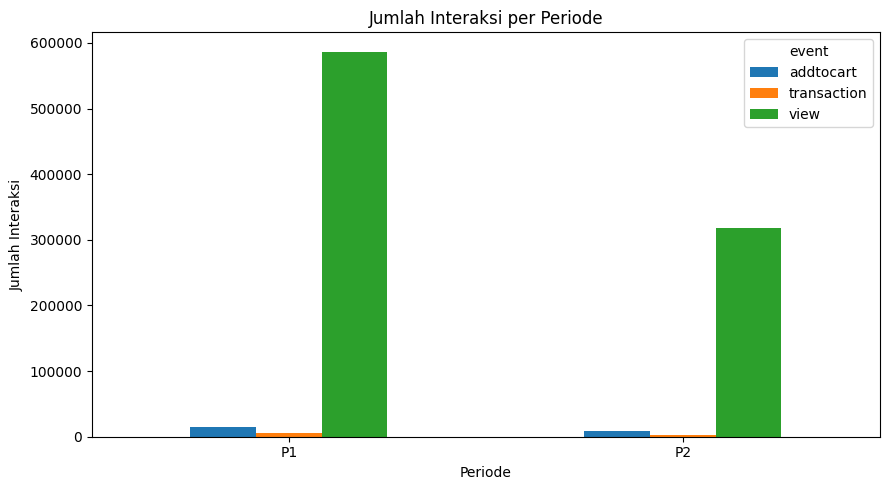

In [15]:
import matplotlib.pyplot as plt

event_counts = filtered.groupby(
    ["period", "event"]
).size().unstack(fill_value=0)

event_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Jumlah Interaksi per Periode")
plt.xlabel("Periode")
plt.ylabel("Jumlah Interaksi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

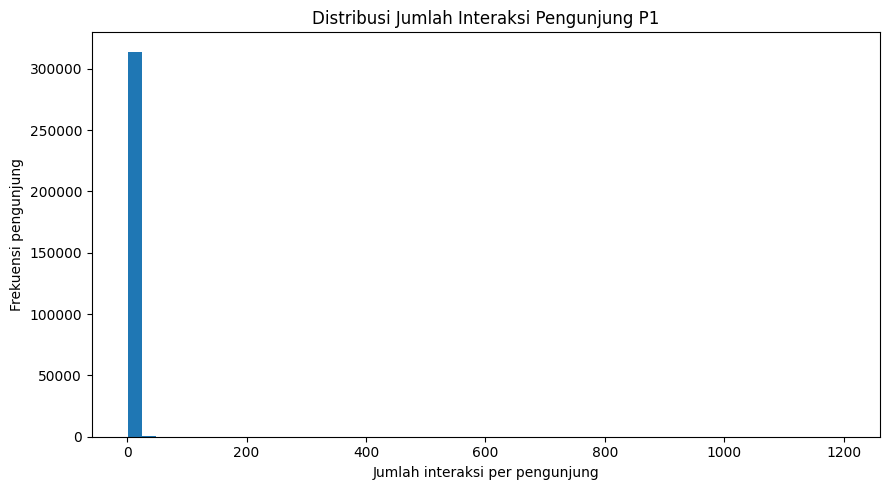

In [16]:
visitor_activity = (
    p1.groupby("visitorid")
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
plt.hist(visitor_activity, bins=50)
plt.title("Distribusi Jumlah Interaksi Pengunjung P1")
plt.xlabel("Jumlah interaksi per pengunjung")
plt.ylabel("Frekuensi pengunjung")
plt.tight_layout()
plt.show()

,jumlah_interaksi
itemid,
5411,1141
309778,807
298009,571
370653,569
257040,513
7943,443
461686,424
111530,414
96924,414


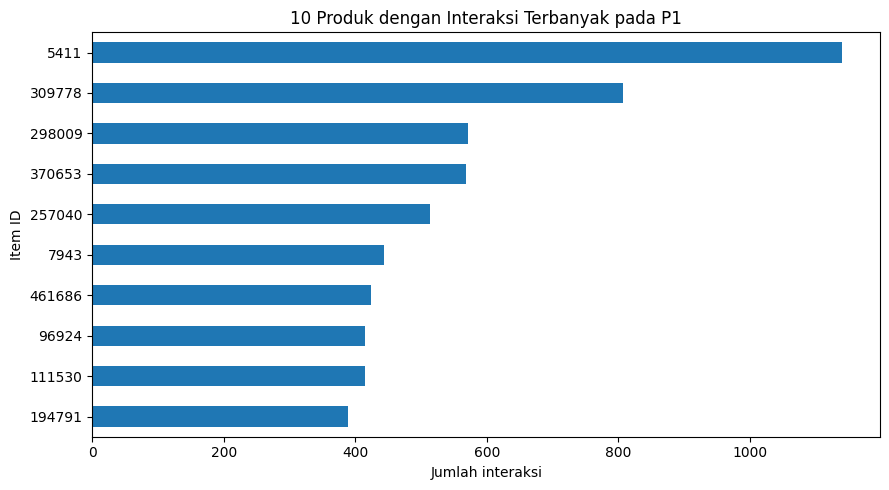

In [17]:
popular_items = (
    p1.groupby("itemid")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

display(popular_items.rename("jumlah_interaksi").to_frame())

popular_items.sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.title("10 Produk dengan Interaksi Terbanyak pada P1")
plt.xlabel("Jumlah interaksi")
plt.ylabel("Item ID")
plt.tight_layout()
plt.show()

### 2.1.3 Vector Space Modelling pada Simpul User

Vector Space Model untuk User dibentuk berdasarkan interaksi pengunjung terhadap item pada periode P1. Setiap baris merepresentasikan seorang pengunjung, sedangkan setiap kolom merepresentasikan sebuah item. Nilai pada matriks menunjukkan ada atau tidaknya interaksi pengunjung terhadap item tersebut.

Karakteristik model dijelaskan melalui jumlah User dan Item, dimensi dan `shape` matriks, serta visualisasi sampel graf menggunakan NetworkX.

In [18]:
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

# Interaksi unik pada P1: satu pasangan user-item dihitung satu kali
interactions_p1 = p1[
    ["visitorid", "itemid"]
].drop_duplicates()

users = np.sort(interactions_p1["visitorid"].unique())
items = np.sort(interactions_p1["itemid"].unique())

user_to_idx = {u: idx for idx, u in enumerate(users)}
item_to_idx = {i: idx for idx, i in enumerate(items)}

rows = interactions_p1["visitorid"].map(user_to_idx).to_numpy()
cols = interactions_p1["itemid"].map(item_to_idx).to_numpy()
values = np.ones(len(interactions_p1), dtype=np.float32)

user_item = csr_matrix(
    (values, (rows, cols)),
    shape=(len(users), len(items)),
    dtype=np.float32
)

item_user = user_item.T.tocsr()

print("Jumlah user:", len(users))
print("Jumlah item:", len(items))
print("Shape User-Item:", user_item.shape)
print("Shape Item-User:", item_user.shape)
print("Jumlah interaksi unik:", user_item.nnz)
print("Kepadatan matriks:", user_item.nnz / (user_item.shape[0] * user_item.shape[1]))

Jumlah user: 314945
Jumlah item: 116517
Shape User-Item: (314945, 116517)
Shape Item-User: (116517, 314945)
Jumlah interaksi unik: 470060
Kepadatan matriks: 1.2809414643660062e-05


In [19]:
user_interaction_counts = np.asarray(
    user_item.sum(axis=1)
).ravel()

print("Dimensi:", user_item.ndim)
print("Shape:", user_item.shape)
print("Jumlah nilai nonzero:", user_item.nnz)
print("Rata-rata item per user:", user_interaction_counts.mean())
print("Median item per user:", np.median(user_interaction_counts))

Dimensi: 2
Shape: (314945, 116517)
Jumlah nilai nonzero: 470060
Rata-rata item per user: 1.4925146
Median item per user: 1.0


In [20]:
for idx in range(min(5, len(users))):
    item_indices = user_item[idx].indices
    print(
        f"User {users[idx]} berinteraksi dengan "
        f"{len(item_indices)} item"
    )

User 8 berinteraksi dengan 1 item
User 13 berinteraksi dengan 2 item
User 14 berinteraksi dengan 1 item
User 17 berinteraksi dengan 1 item
User 23 berinteraksi dengan 2 item


In [21]:
item_interaction_counts = np.asarray(
    item_user.sum(axis=1)
).ravel()

print("Dimensi:", item_user.ndim)
print("Shape:", item_user.shape)
print("Jumlah nilai nonzero:", item_user.nnz)
print("Rata-rata user per item:", item_interaction_counts.mean())
print("Median user per item:", np.median(item_interaction_counts))

Dimensi: 2
Shape: (116517, 314945)
Jumlah nilai nonzero: 470060
Rata-rata user per item: 4.034261
Median user per item: 2.0


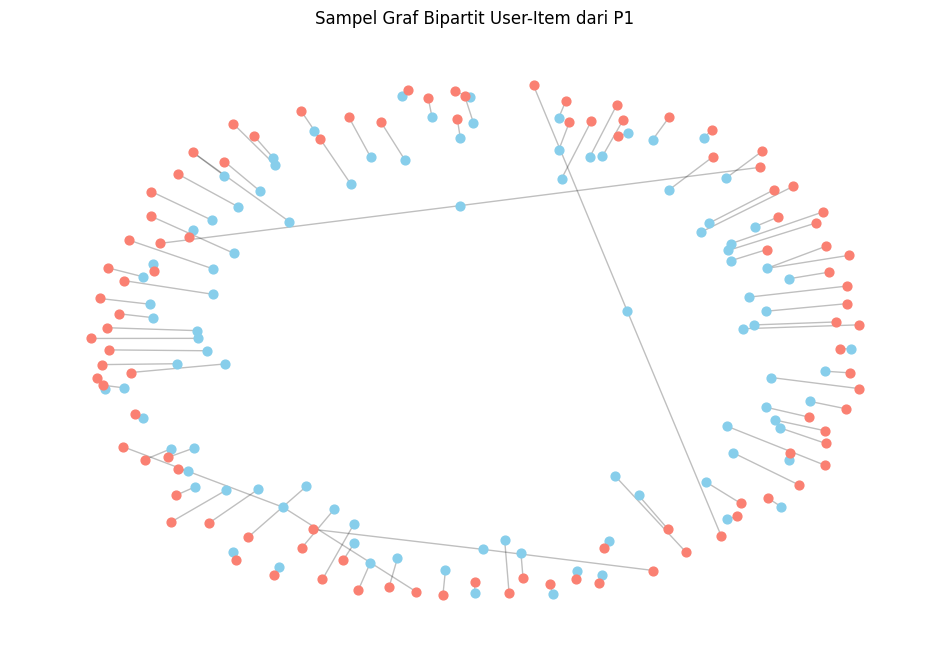

In [22]:
import networkx as nx

sample = interactions_p1.head(100)

G = nx.DiGraph()

for row in sample.itertuples(index=False):
    G.add_edge(
        f"U{row.visitorid}",
        f"I{row.itemid}"
    )

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42)

user_nodes = [n for n in G.nodes if n.startswith("U")]
item_nodes = [n for n in G.nodes if n.startswith("I")]

nx.draw_networkx_nodes(
    G, pos, nodelist=user_nodes,
    node_size=40, node_color="skyblue"
)
nx.draw_networkx_nodes(
    G, pos, nodelist=item_nodes,
    node_size=40, node_color="salmon"
)
nx.draw_networkx_edges(G, pos, alpha=0.25, arrows=False)

plt.title("Sampel Graf Bipartit User-Item dari P1")
plt.axis("off")
plt.show()

In [23]:
print("User-User: ukuran matriks teoritis =", len(users), "x", len(users))
print("Item-Item: ukuran matriks teoritis =", len(items), "x", len(items))

print("Jumlah elemen User-User:", len(users) ** 2)
print("Jumlah elemen Item-Item:", len(items) ** 2)

User-User: ukuran matriks teoritis = 314945 x 314945
Item-Item: ukuran matriks teoritis = 116517 x 116517
Jumlah elemen User-User: 99190353025
Jumlah elemen Item-Item: 13576211289


### 2.1.4 Vector Space Modelling pada Simpul Item

Vector Space Model untuk Item dibentuk dengan melihat interaksi pengunjung terhadap setiap item. Dalam representasi Item–User, baris menunjukkan item dan kolom menunjukkan pengunjung. Setiap item direpresentasikan sebagai vektor berdasarkan pola interaksi pengunjung.

Dimensi, `shape`, jumlah interaksi, dan visualisasi sampel graf digunakan untuk menjelaskan karakteristik representasi item dan mendukung perbandingan dengan model User.

### 2.1.5 Memilih Proyeksi Terbaik

Pada bagian ini, dilakukan perbandingan matriks user-item dan item-user berdasarkan ukuran serta kepadatannya. Perbandingan ini digunakan untuk menentukan proyeksi yang lebih sesuai untuk menghitung kemiripan antaritem atau antaruser. Pemilihan proyeksi mempertimbangkan efisiensi komputasi dan kebutuhan analisis rekomendasi.

In [24]:
print(
    "Kepadatan User-Item:",
    user_item.nnz / (user_item.shape[0] * user_item.shape[1])
)

print(
    "Kepadatan Item-User:",
    item_user.nnz / (item_user.shape[0] * item_user.shape[1])
)

Kepadatan User-Item: 1.2809414643660062e-05
Kepadatan Item-User: 1.2809414643660062e-05


### 2.1.6 Menghitung Kemiripan Antaritem dan Menyimpan ke Neo4j

Pada bagian ini, kemiripan antaritem dihitung menggunakan *cosine similarity* berdasarkan representasi vektor Item–User. Satu item acuan dipilih berdasarkan jumlah interaksi pada periode P1, kemudian lima item lain dengan nilai kemiripan tertinggi ditampilkan. Hasil kemiripan tersebut selanjutnya disimpan ke Neo4j sebagai relasi `SIMILAR_TO` beserta skor kemiripannya.


In [25]:
from sklearn.metrics.pairwise import cosine_similarity

item_popularity = np.asarray(item_user.sum(axis=1)).ravel()

# Item populer; indeks item sudah diurutkan berdasarkan ID
reference_idx = int(np.argmax(item_popularity))
reference_item = int(items[reference_idx])

print("Item acuan:", reference_item)
print("Jumlah interaksi unik:", int(item_popularity[reference_idx]))

Item acuan: 5411
Jumlah interaksi unik: 1030


### 2.1.7 Menghitung Similarity pada Hasil Graf

In [27]:
reference_vector = item_user[reference_idx]

similarity_scores = cosine_similarity(
    reference_vector,
    item_user
).ravel()

# Urutkan similarity tertinggi, kecuali item itu sendiri
ranked_indices = np.argsort(-similarity_scores)
ranked_indices = [
    idx for idx in ranked_indices
    if idx != reference_idx
]

top5_indices = ranked_indices[:5]

top5_similar_items = pd.DataFrame({
    "item_id": items[top5_indices],
    "similarity": similarity_scores[top5_indices]
})

display(top5_similar_items)

,item_id,similarity
0,33030,0.182343
1,33956,0.110450
2,358234,0.101764
3,375492,0.074089
4,459936,0.068549


In [28]:
similarity_records = [
    {
        "item_id": int(items[idx]),
        "score": float(similarity_scores[idx])
    }
    for idx in top5_indices
]

write_similarity_query = """
MATCH (source:Item {itemId: $reference_item})
UNWIND $similarities AS sim
MATCH (target:Item {itemId: sim.item_id})
MERGE (source)-[r:SIMILAR_TO]->(target)
SET r.score = sim.score,
    r.method = 'cosine_item_item',
    r.period = 'P1'
"""

with driver.session(database=DATABASE) as session:
    session.run(
        write_similarity_query,
        reference_item=reference_item,
        similarities=similarity_records
    ).consume()

print("Lima relasi similarity berhasil disimpan.")

Lima relasi similarity berhasil disimpan.


## 2.2 Analytics

Bagian ini menggunakan periode P1 sebagai data untuk membangun rekomendasi dan periode P2 untuk mengevaluasi hasilnya. Rekomendasi item dibentuk berdasarkan kemiripan antaritem dengan pendekatan *K-Nearest Neighbors* (KNN). Kinerja rekomendasi dinilai menggunakan metrik Hit@5 dan NDCG@5.


In [29]:
import pandas as pd
from pathlib import Path

# Membaca data yang sudah difilter sebelumnya
p1_path = Path("data/events_P1.csv")
p2_path = Path("data/events_P2.csv")

print("File P1 ditemukan:", p1_path.exists())
print("File P2 ditemukan:", p2_path.exists())

# Muat data
p1 = pd.read_csv(p1_path)
p2 = pd.read_csv(p2_path)

print("\nUkuran data P1:", p1.shape)
print("Ukuran data P2:", p2.shape)

print("\nKolom data P1:")
print(p1.columns.tolist())

print("\nContoh data P1:")
display(p1.head())

print("\nDistribusi event P1:")
display(p1["event"].value_counts())

print("\nDistribusi event P2:")
display(p2["event"].value_counts())


File P1 ditemukan: True
File P2 ditemukan: True

Ukuran data P1: (606634, 5)
Ukuran data P2: (329403, 5)

Kolom data P1:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Contoh data P1:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Distribusi event P1:


event
view           586741
addtocart       14960
transaction      4933
Name: count, dtype: int64


Distribusi event P2:


event
view           318427
addtocart        8174
transaction      2802
Name: count, dtype: int64

### 2.2.1 Menyiapkan Data dan Membuat Rekomendasi KNN

Data P1 dan P2 dibaca kembali untuk memastikan data pelatihan dan pengujian tersedia. Rekomendasi dibentuk dari item yang pernah dilihat oleh visitor terpilih pada P1. Tetangga item dicari berdasarkan jarak cosine, item yang sudah dilihat dikeluarkan dari kandidat, lalu kandidat diberi skor berdasarkan kemiripan positif. Lima item dengan skor tertinggi ditampilkan sebagai rekomendasi.


In [35]:
from sklearn.neighbors import NearestNeighbors

# Pilih visitor pertama yang memiliki interaksi pada P1
selected_visitor = interactions_p1["visitorid"].iloc[0]

# Cari tetangga terdekat berdasarkan kemiripan item
n_neighbors = min(21, item_user.shape[0])

knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=n_neighbors
)

knn.fit(item_user)

distances, neighbor_indices = knn.kneighbors(item_user)

# Item yang pernah dilihat visitor pada P1
seen_items = set(
    interactions_p1.loc[
        interactions_p1["visitorid"] == selected_visitor,
        "itemid"
    ]
)

# Hitung skor rekomendasi
scores = {}

for item in seen_items:
    item_idx = item_to_idx[item]

    for neighbor_idx, distance in zip(
        neighbor_indices[item_idx][1:],
        distances[item_idx][1:]
    ):
        candidate_item = items[neighbor_idx]

        if candidate_item in seen_items:
            continue

        similarity = 1 - distance

        if similarity > 0:
            scores[candidate_item] = (
                scores.get(candidate_item, 0) + similarity
            )

# Ambil maksimal lima rekomendasi
ranked_items = sorted(
    scores.items(),
    key=lambda x: x[1],
    reverse=True
)[:5]

recommendations = pd.DataFrame(
    ranked_items,
    columns=["itemid", "score"]
)

print("Visitor terpilih:", selected_visitor)
print("Jumlah item yang sudah dilihat:", len(seen_items))
print("Jumlah rekomendasi:", len(recommendations))

display(recommendations)

Visitor terpilih: 257597
Jumlah item yang sudah dilihat: 2
Jumlah rekomendasi: 5


,itemid,score
0,97139,0.248452
1,238777,0.243108
2,73646,0.235702
3,381,0.235702
4,393910,0.210819


### 2.2.2 Evaluasi Rekomendasi Menggunakan Hit@5 dan NDCG@5

Rekomendasi dievaluasi menggunakan interaksi visitor pada periode P2 sebagai acuan relevansi. Hit@5 bernilai 1 apabila setidaknya satu dari lima item rekomendasi muncul pada data relevan, dan 0 jika tidak ada yang cocok. NDCG@5 mempertimbangkan relevansi sekaligus posisi item yang relevan pada daftar rekomendasi; nilai yang lebih tinggi menunjukkan urutan rekomendasi yang lebih baik.


In [36]:
# Item relevan visitor pada periode testing P2
relevant_items = set(
    p2.loc[
        p2["visitorid"] == selected_visitor,
        "itemid"
    ].unique()
)

# Lima rekomendasi terbaru, sesuai urutan skor
recommended_items = recommendations["itemid"].tolist()[:5]

# Relevansi biner: 1 jika item rekomendasi ada di P2
hits = [
    int(item in relevant_items)
    for item in recommended_items
]

# Hit@5
hit_at_5 = int(any(hits))

# DCG@5
dcg = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(hits)
)

# Ideal DCG@5
ideal_hits = min(len(relevant_items), 5)
idcg = sum(
    1 / np.log2(rank + 2)
    for rank in range(ideal_hits)
)

# NDCG@5
ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

print("Visitor terpilih:", selected_visitor)
print("Item relevan di P2:", sorted(relevant_items))
print("Top-5 rekomendasi:", recommended_items)
print("Relevansi tiap peringkat:", hits)
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))


Visitor terpilih: 257597
Item relevan di P2: []
Top-5 rekomendasi: [97139, 238777, 73646, 381, 393910]
Relevansi tiap peringkat: [0, 0, 0, 0, 0]
Hit@5: 0
NDCG@5: 0.0


### 2.2.3 Perluasan Kandidat Rekomendasi

Pada tahap ini, jumlah tetangga item diperluas agar pencarian kandidat rekomendasi dapat mempertimbangkan lebih banyak item yang mirip. Rekomendasi dihitung kembali dengan prinsip yang sama, yaitu mengecualikan item yang sudah dilihat dan mengurutkan kandidat berdasarkan akumulasi skor kemiripan positif. Hasilnya dapat dibandingkan dengan rekomendasi sebelumnya.


In [39]:
# Perluas jumlah tetangga item untuk mencari kandidat rekomendasi
n_neighbors_expanded = min(21, len(items))

knn_expanded = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=n_neighbors_expanded
)

# Gunakan item_user, bukan item_user_matrix
knn_expanded.fit(item_user)

expanded_distances, expanded_neighbor_indices = knn_expanded.kneighbors(
    item_user
)

# Ambil item yang pernah dilihat visitor terpilih pada P1
seen_items = set(
    interactions_p1.loc[
        interactions_p1["visitorid"] == selected_visitor,
        "itemid"
    ]
)

# Hitung skor kandidat berdasarkan kemiripan positif
scores = {}

for item in seen_items:
    item_idx = item_to_idx[item]

    for neighbor_idx, distance in zip(
        expanded_neighbor_indices[item_idx][1:],
        expanded_distances[item_idx][1:]
    ):
        candidate_item = items[neighbor_idx]

        if candidate_item in seen_items:
            continue

        similarity = 1 - distance

        if similarity > 0:
            scores[candidate_item] = (
                scores.get(candidate_item, 0) + similarity
            )

# Ambil maksimal lima kandidat dengan skor tertinggi
ranked_items = sorted(
    scores.items(),
    key=lambda x: x[1],
    reverse=True
)[:5]

recommendations = pd.DataFrame(
    ranked_items,
    columns=["itemid", "score"]
)

print("Visitor terpilih:", selected_visitor)
print("Jumlah item yang sudah dilihat:", len(seen_items))
print("Jumlah rekomendasi:", len(recommendations))
display(recommendations)

Visitor terpilih: 257597
Jumlah item yang sudah dilihat: 2
Jumlah rekomendasi: 5


,itemid,score
0,97139,0.248452
1,238777,0.243108
2,73646,0.235702
3,381,0.235702
4,393910,0.210819


## Kesimpulan

Pada notebook ini, data interaksi RetailRocket dipisahkan menjadi periode P1 dan P2, dieksplorasi melalui Python dan Neo4j, lalu direpresentasikan menggunakan Vector Space Model pada simpul User dan Item. Kemiripan antaritem dihitung menggunakan *cosine similarity* dan disimpan pada graf Neo4j sebagai relasi `SIMILAR_TO`. Selanjutnya, pendekatan KNN digunakan untuk menghasilkan rekomendasi item dan dievaluasi menggunakan Hit@5 serta NDCG@5 pada periode P2.
